# Car Price Prediction with Machine Learning

**Objective:** Build a regression model that predicts the selling price of a used car from features such as brand, age, mileage, fuel type and transmission.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

**Dataset:** `car_data.csv`

### Import Libraries

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

#### 📚 Libraries and Functions Used

| Library / Function | Purpose |
|---|---|
| **pandas** | Data manipulation and analysis |
| **numpy** | Numerical operations and calculations |
| **matplotlib.pyplot** | Data visualization and plotting charts |
| **seaborn** | Statistical data visualization |
| **train_test_split** | Split the dataset into training and testing sets |
| **cross_val_score** | Evaluate model performance using cross-validation |
| **KFold** | Divide data into folds for cross-validation |
| **LinearRegression** | Build a linear regression model for price prediction |
| **RandomForestRegressor** | Build an ensemble regression model using multiple decision trees |
| **GradientBoostingRegressor** | Build a boosting regression model to improve prediction accuracy |
| **mean_absolute_error (MAE)** | Measure the average absolute difference between actual and predicted prices |
| **mean_squared_error (MSE)** | Measure the average squared difference between actual and predicted prices |
| **r2_score (R²)** | Measure how well the model explains the variation in car prices |

### Load `car data.csv` **Dataset**

In [37]:
file_path = '/content/drive/MyDrive/OASIS INFOBYTE Internship/Task3/car data.csv'
# Load the dataset file
df = pd.read_csv(file_path)
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Inspecting the data

In [38]:
print("Shape:", df.shape)
print("Nulls per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

Shape: (301, 9)
Nulls per column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64
Duplicate rows: 2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [39]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [40]:
for column in df.columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- Car_Name ---
Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     11
brio                         10
ciaz                          9
i20                           9
innova                        9
grand i10                     8
Royal Enfield Classic 350     7
amaze                         7
jazz                          7
eon                           6
sx4                           6
ertiga                        6
swift                         5
alto k10                      5
i10                           5
dzire                         4
Royal Enfield Thunder 350     4
etios liva                    4
wagon r                       4
Bajaj Pulsar 150              4
ritz                          4
Honda CB Hornet 160R          3
Bajaj Avenger 220             3
Yamaha FZ S V 2.0             3
xcent                         3
Bajaj Pulsar NS 200           3
TVS Apache RTR 160            3
etios cross  

#### **Observations**: Inspecting the data
- The raw data has 301 rows and 9 columns.
- There are no missing values and 2 duplicate rows.
- Prices are in lakhs of rupees. The mean selling price is well above the median, so prices are skewed to the right.
- `Kms_Driven` has an extreme value of 500,000 km that I should keep in mind later.

### Data Cleaning

In [41]:
# Remove stray spaces from column names
df.columns = df.columns.str.strip()

# Make the categorical text consistent (strip spaces, same capitalisation)
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    df[col] = df[col].str.strip().str.title()
df["Fuel_Type"] = df["Fuel_Type"].replace({"Cng": "CNG"})   # keep CNG in capitals

# Car_Name: remove extra inner spaces and lower-case it
df["Car_Name"] = df["Car_Name"].str.split().str.join(" ").str.lower()

# Confirm the categorical values are consistent
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    print(col, "->", df[col].unique())

Fuel_Type -> ['Petrol' 'Diesel' 'CNG']
Seller_Type -> ['Dealer' 'Individual']
Transmission -> ['Manual' 'Automatic']


In [42]:
# Show the duplicate rows, then remove them
print(df[df.duplicated(keep=False)])

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df.shape)

    Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
15    ertiga  2016           7.75          10.79       43000    Diesel   
17    ertiga  2016           7.75          10.79       43000    Diesel   
51  fortuner  2015          23.00          30.61       40000    Diesel   
93  fortuner  2015          23.00          30.61       40000    Diesel   

   Seller_Type Transmission  Owner  
15      Dealer       Manual      0  
17      Dealer       Manual      0  
51      Dealer    Automatic      0  
93      Dealer    Automatic      0  
Shape after cleaning: (299, 9)


#### **Observations**
- The categorical columns were already consistent, so the casing fix changed nothing here, but it protects the code if the data changes.
- The 2 duplicates (one Ertiga and one Fortuner) were removed, leaving 299 rows.

### Feature Engineering

In [43]:
print(df['Car_Name'].value_counts())

Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     10
brio                         10
i20                           9
innova                        9
ciaz                          9
grand i10                     8
amaze                         7
jazz                          7
royal enfield classic 350     7
eon                           6
sx4                           6
ertiga                        5
swift                         5
alto k10                      5
i10                           5
ritz                          4
dzire                         4
royal enfield thunder 350     4
etios liva                    4
bajaj pulsar ns 200           4
bajaj pulsar 150              4
wagon r                       4
honda cb hornet 160r          3
xcent                         3
bajaj avenger 220             3
tvs apache rtr 160            3
yamaha fz s v 2.0             3
etios g                       3

In [44]:
print(df['Car_Name'].unique())

['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire' 'alto k10' 'ignis' '800' 'baleno' 'omni'
 'fortuner' 'innova' 'corolla altis' 'etios cross' 'etios g' 'etios liva'
 'corolla' 'etios gd' 'camry' 'land cruiser' 'royal enfield thunder 500'
 'um renegade mojave' 'ktm rc200' 'bajaj dominar 400'
 'royal enfield classic 350' 'ktm rc390' 'hyosung gt250r'
 'royal enfield thunder 350' 'ktm 390 duke' 'mahindra mojo xt300'
 'bajaj pulsar rs200' 'royal enfield bullet 350'
 'royal enfield classic 500' 'bajaj avenger 220' 'bajaj avenger 150'
 'honda cb hornet 160r' 'yamaha fz s v 2.0' 'yamaha fz 16'
 'tvs apache rtr 160' 'bajaj pulsar 150' 'honda cbr 150' 'hero extreme'
 'bajaj avenger 220 dtsi' 'bajaj avenger 150 street' 'yamaha fz v 2.0'
 'bajaj pulsar ns 200' 'bajaj pulsar 220 f' 'tvs apache rtr 180'
 'hero passion x pro' 'yamaha fazer' 'honda activa 4g' 'tvs sport'
 'honda dream yuga' 'bajaj avenger street 220' 'hero splender ismart'
 'activa 3g' 'hero

In [45]:
print(df['Car_Name'].value_counts().to_string())

Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     10
brio                         10
i20                           9
innova                        9
ciaz                          9
grand i10                     8
amaze                         7
jazz                          7
royal enfield classic 350     7
eon                           6
sx4                           6
ertiga                        5
swift                         5
alto k10                      5
i10                           5
ritz                          4
dzire                         4
royal enfield thunder 350     4
etios liva                    4
bajaj pulsar ns 200           4
bajaj pulsar 150              4
wagon r                       4
honda cb hornet 160r          3
xcent                         3
bajaj avenger 220             3
tvs apache rtr 160            3
yamaha fz s v 2.0             3
etios g                       3

#### Extracting the brand
In this dataset most `Car_Name` values are model names only (for example `city`, `swift`, `verna`), so taking the first word would return the model, not the brand. I map each car model to its brand with a dictionary. The bike rows (for example `Bajaj Pulsar 150`) already start with the brand name.

In [46]:
# See what Car_Name looks like before deciding how to extract the brand
print("Unique names:", df["Car_Name"].nunique())
df["Car_Name"].value_counts().head(15)

Unique names: 97


,count
Car_Name,
city,26
corolla altis,16
verna,14
fortuner,10
brio,10
i20,9
innova,9
ciaz,9
grand i10,8


In [47]:
# Car models grouped by brand
car_brands = {
    "Honda": ["city", "amaze", "brio", "jazz"],
    "Toyota": ["corolla altis", "corolla", "fortuner", "innova", "etios liva",
               "etios cross", "etios g", "etios gd", "camry", "land cruiser"],
    "Hyundai": ["verna", "i20", "grand i10", "i10", "eon", "xcent", "creta", "elantra"],
    "Maruti Suzuki": ["ciaz", "sx4", "ertiga", "swift", "alto k10", "alto 800", "ritz",
                      "wagon r", "dzire", "vitara brezza", "s cross", "ignis", "800",
                      "baleno", "omni"],
}

# Flip it into {model: brand} so each model can be looked up directly
model_to_brand = {m: b for b, models in car_brands.items() for m in models}

# Bike names start with the brand (order matters: "hero honda" before "honda")
bike_prefixes = [("royal enfield", "Royal Enfield"), ("bajaj", "Bajaj"),
                 ("hero honda", "Hero"), ("hero", "Hero"), ("honda", "Honda"),
                 ("activa", "Honda"), ("yamaha", "Yamaha"), ("tvs", "TVS"),
                 ("ktm", "KTM"), ("hyosung", "Hyosung"), ("um ", "UM"),
                 ("mahindra", "Mahindra"), ("suzuki", "Suzuki")]

def get_brand(name):
    # Car models: look the name up in the dictionary
    if name in model_to_brand:
        return model_to_brand[name]
    # Bikes: the name starts with the brand
    for prefix, brand in bike_prefixes:
        if name.startswith(prefix):
            return brand
    return "Other"

df["Brand"] = df["Car_Name"].apply(get_brand)

# Flag each row as a car or a bike
df["Vehicle_Type"] = np.where(df["Car_Name"].isin(model_to_brand), "Car", "Bike")

print(df["Vehicle_Type"].value_counts())
print()
print(df["Brand"].value_counts())

Vehicle_Type
Car     198
Bike    101
Name: count, dtype: int64

Brand
Honda            70
Hyundai          50
Maruti Suzuki    49
Toyota           49
Bajaj            25
Royal Enfield    17
Hero             15
Yamaha            8
TVS               8
KTM               4
UM                1
Mahindra          1
Hyosung           1
Suzuki            1
Name: count, dtype: int64


In [48]:
df[df["Brand"] == "Other"]

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Vehicle_Type


##### **Observations**
- The file contains 198 cars and 101 motorbikes, even though the task is about cars.
- Every row got a brand (none fell into "Other").

#### Car age
Age is calculated from `Year`. The reference year is the latest year in the data plus one, so ages match the time the data was collected.

In [49]:
# Reference year = 2026
reference_year = 2026
df["Car_Age"] = reference_year - df["Year"]

print("Reference year:", reference_year)
df[["Car_Name", "Brand", "Year", "Car_Age", "Selling_Price"]].head()

Reference year: 2026


,Car_Name,Brand,Year,Car_Age,Selling_Price
0,ritz,Maruti Suzuki,2014,12,3.35
1,sx4,Maruti Suzuki,2013,13,4.75
2,ciaz,Maruti Suzuki,2017,9,7.25
3,wagon r,Maruti Suzuki,2011,15,2.85
4,swift,Maruti Suzuki,2014,12,4.60


##### **Observations**
- `Car_Age` replaces `Year` as a more meaningful feature: a higher value means an older car.

### EDA

#### Distribution of selling prices

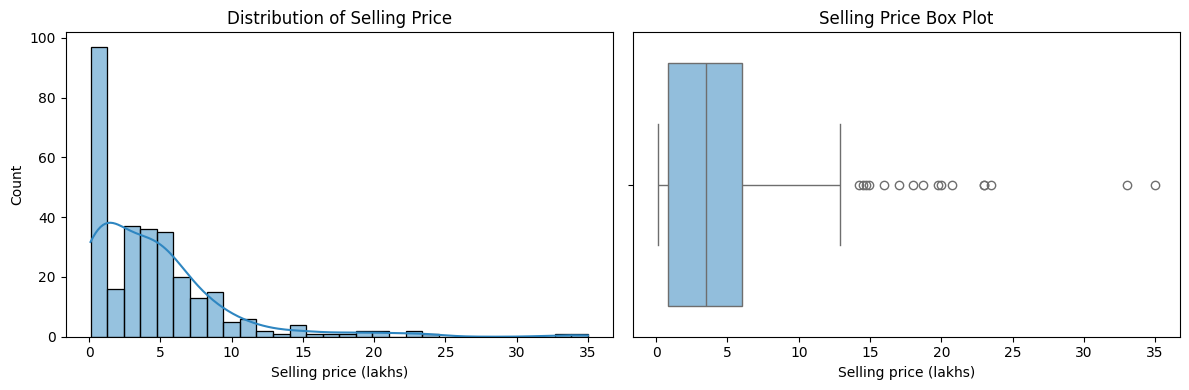

Skewness: 2.54


,Selling_Price
count,299.00
mean,4.59
std,4.98
min,0.10
25%,0.85
50%,3.51
75%,6.00
max,35.00


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram with a smooth density line
sns.histplot(df["Selling_Price"], bins=30, kde=True, color="#2e86c1", ax=axes[0])
axes[0].set_title("Distribution of Selling Price")
axes[0].set_xlabel("Selling price (lakhs)")

# Box plot to show the outliers
sns.boxplot(x=df["Selling_Price"], color="#85c1e9", ax=axes[1])
axes[1].set_title("Selling Price Box Plot")
axes[1].set_xlabel("Selling price (lakhs)")

plt.tight_layout()
plt.show()

print("Skewness:", round(df["Selling_Price"].skew(), 2))
df["Selling_Price"].describe().round(2)

##### **Observations**
- Prices are strongly right-skewed .
- The box plot flags those expensive cars as outliers. They are real cars, not errors, so I keep them.

#### Price vs fuel type

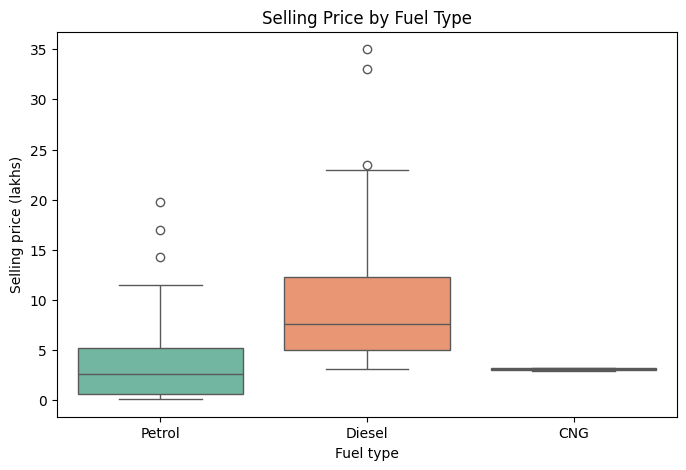

,count,median,mean
Fuel_Type,,,
CNG,2,3.10,3.10
Diesel,58,7.60,10.10
Petrol,239,2.65,3.26


In [51]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price", hue="Fuel_Type", palette="Set2", legend=False)
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (lakhs)")
plt.show()

# Numbers behind the box plot
df.groupby("Fuel_Type")["Selling_Price"].agg(["count", "median", "mean"]).round(2)

##### **Observations**
- Diesel cars have the highest median price (about 7 lakhs), followed by Petrol (about 4).
- CNG has only 2 cars, so its box plot should not be trusted.
- Diesel cars are often larger and more expensive models.

#### Price vs car age

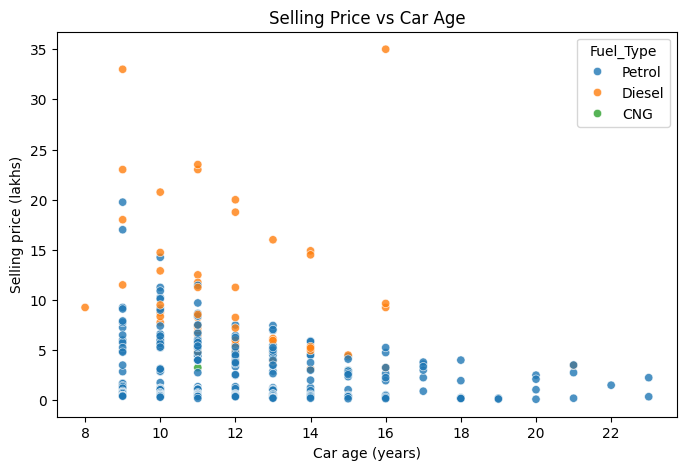

Correlation (age vs price): -0.23


In [52]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Car_Age", y="Selling_Price", hue="Fuel_Type", alpha=0.8)
plt.title("Selling Price vs Car Age")
plt.xlabel("Car age (years)")
plt.ylabel("Selling price (lakhs)")
plt.show()

print("Correlation (age vs price):", round(df["Car_Age"].corr(df["Selling_Price"]), 2))

##### **Observations**
- Older cars tend to sell for less.
- Cars of the same age vary widely in price.

### Encoding Categorical Variables

In [53]:
# Target: what we want to predict
y = df["Selling_Price"]

# Features: everything except the target and the columns we replaced
X = df.drop(columns=["Selling_Price", "Car_Name", "Year","Vehicle_Type"])

print("Columns before encoding:", list(X.columns))

Columns before encoding: ['Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Brand', 'Car_Age']


In [54]:
# One-hot encode the four text columns
X = pd.get_dummies(X, columns=["Fuel_Type", "Seller_Type", "Transmission", "Brand"],
                   drop_first=True, dtype=int)

print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (299, 21)


,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual,Brand_Hero,Brand_Honda,Brand_Hyosung,Brand_Hyundai,Brand_KTM,Brand_Mahindra,Brand_Maruti Suzuki,Brand_Royal Enfield,Brand_Suzuki,Brand_TVS,Brand_Toyota,Brand_UM,Brand_Yamaha
0,5.59,27000,0,12,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
1,9.54,43000,0,13,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
2,9.85,6900,0,9,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
3,4.15,5200,0,15,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
4,6.87,42450,0,12,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0


In [55]:
# Every column must be numeric before training
print(X.dtypes)
print("Nulls:", X.isnull().sum().sum())

Present_Price             float64
Kms_Driven                  int64
Owner                       int64
Car_Age                     int64
Fuel_Type_Diesel            int64
Fuel_Type_Petrol            int64
Seller_Type_Individual      int64
Transmission_Manual         int64
Brand_Hero                  int64
Brand_Honda                 int64
Brand_Hyosung               int64
Brand_Hyundai               int64
Brand_KTM                   int64
Brand_Mahindra              int64
Brand_Maruti Suzuki         int64
Brand_Royal Enfield         int64
Brand_Suzuki                int64
Brand_TVS                   int64
Brand_Toyota                int64
Brand_UM                    int64
Brand_Yamaha                int64
dtype: object
Nulls: 0


### Feature correlation heatmap

In [56]:
# Join the target with the encoded features and compute pairwise correlations
corr = pd.concat([y, X], axis=1).corr()

print("Matrix shape:", corr.shape)

Matrix shape: (22, 22)


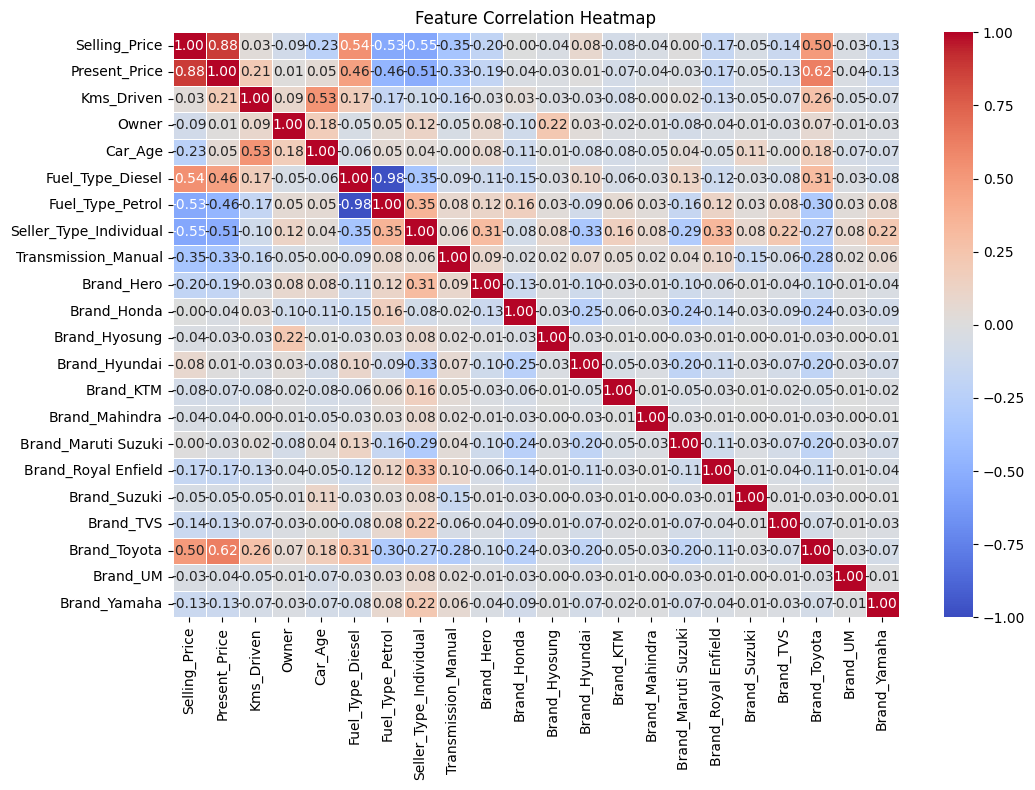

In [57]:
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [58]:
# Correlation of every feature with the selling price, strongest first
corr["Selling_Price"].drop("Selling_Price").sort_values(ascending=False).round(2)

,Selling_Price
Present_Price,0.88
Fuel_Type_Diesel,0.54
Brand_Toyota,0.50
Brand_Hyundai,0.08
Kms_Driven,0.03
Brand_Maruti Suzuki,0.00
Brand_Honda,-0.00
Brand_UM,-0.03
Brand_Hyosung,-0.04
Brand_Mahindra,-0.04


##### **Observations**
- `Present_Price` has by far the strongest link to selling price (about 0.88).

### Train/Test Split

In [59]:
# random_state makes the split repeatable, so you get the same rows every run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (239, 21)  Test: (60, 21)


### 8. Model Training

I train three regression models and compare them in the next section:
- **Linear Regression:** a simple baseline that fits one straight-line formula.
- **Random Forest:** many decision trees averaged together, which can capture non-linear patterns.
- **Gradient Boosting:** trees built one after another, each correcting the errors of the previous one.

In [61]:
# Put the models in a dictionary so we can loop over them
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

print("Models ready:", list(models.keys()))

Models ready: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


In [62]:
# Train each model on the TRAINING set only
for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained:", name)

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


In [63]:
# R2 on the data the model learned from vs on unseen data
for name, model in models.items():
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    print(f"{name:20s} train R2 = {train_r2:.3f} | test R2 = {test_r2:.3f}")

Linear Regression    train R2 = 0.907 | test R2 = 0.750
Random Forest        train R2 = 0.983 | test R2 = 0.502
Gradient Boosting    train R2 = 0.997 | test R2 = 0.693


### 9. Model Evaluation

I score each model on the **test set** with three metrics:
- **MAE** (mean absolute error): the average size of the error, in lakhs. Lower is better.
- **RMSE** (root mean squared error): like MAE but it punishes big mistakes more. Lower is better.
- **R²**: the share of the price variation the model explains. 1.0 is perfect and 0 is no better than guessing the average.

In [64]:
# Predict on the unseen test set and compute the three metrics
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),   # square root of MSE
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,MAE,RMSE,R2
Model,,,
Linear Regression,1.514,2.536,0.750
Random Forest,1.460,3.581,0.502
Gradient Boosting,1.202,2.811,0.693


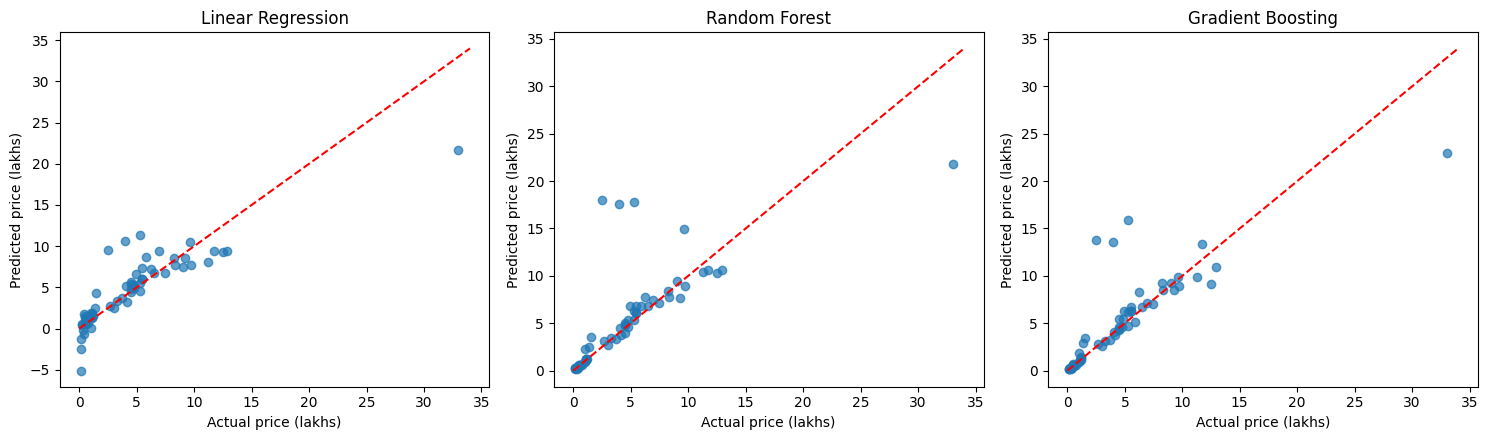

In [65]:
# One scatter plot per model: points on the red line are perfect predictions
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.7)
    lim = [0, max(y_test.max(), pred.max()) + 1]
    ax.plot(lim, lim, "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual price (lakhs)")
    ax.set_ylabel("Predicted price (lakhs)")
plt.tight_layout()
plt.show()

#####**Observations**
- Linear Regression has the best R² (0.750) and the lowest RMSE (2.536), so it explains the most price variation and makes the fewest large mistakes.
- Gradient Boosting has the lowest MAE (1.202 lakhs), so it is the closest on a typical car, but its R² (0.693) is lower than Linear Regression's.
- Random Forest is the weakest model here (R² 0.502, RMSE 3.581). Its MAE (1.460) is close to the others, but its RMSE is much larger, so most predictions are fine and a few are far off.
- The gap between RMSE and MAE shows this: Linear Regression's RMSE is about 1.7 times its MAE, while Random Forest's is about 2.5 times. Large errors on a few vehicles drive Random Forest's RMSE.
- These results mix cars and motorbikes, which sit on very different price scales. Tree models predict by averaging similar training rows, so they struggle with the few expensive vehicles, while the straight-line model copes better.
- The ranking depends on the metric (best MAE: Gradient Boosting, best R² and RMSE: Linear Regression), so no single model is the clear winner.

### Feature Importance

In [66]:
# Best model = highest R2 on the test set
best_name = results_df["R2"].idxmax()
best_model = models[best_name]

print("Best model:", best_name)

Best model: Linear Regression


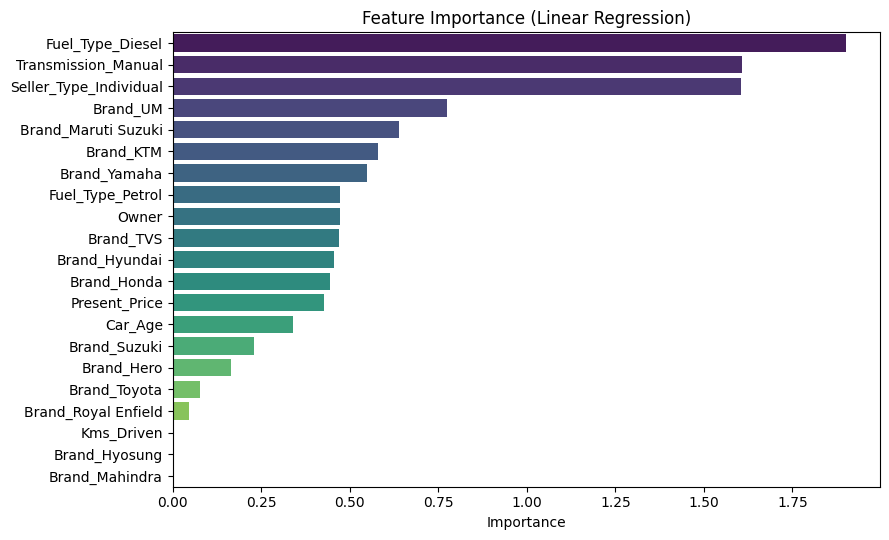

,0
Fuel_Type_Diesel,1.902
Transmission_Manual,1.607
Seller_Type_Individual,1.605
Brand_UM,0.774
Brand_Maruti Suzuki,0.639
Brand_KTM,0.580
Brand_Yamaha,0.549
Fuel_Type_Petrol,0.472
Owner,0.472
Brand_TVS,0.469


In [67]:
# Tree models have feature_importances_; Linear Regression uses the size of its coefficients
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X.columns)
else:
    importance = pd.Series(best_model.coef_, index=X.columns).abs()

importance = importance.sort_values(ascending=False)

plt.figure(figsize=(9, 5.5))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index,
            palette="viridis", legend=False)
plt.title(f"Feature Importance ({best_name})")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

importance.round(3)